In [1]:
import numpy as np

----------------------------------------------------------------------
Real-life example:   Perceptron for Irrigation Decision

A farmer wants a simple automated system to decide whether to turn
irrigation ON (1) or OFF (0) for a crop field, based on two binary
sensor readings:

| Feature   | Meaning           |
| --------- | ----------------- |
| Feature 1 | Soil Dry?         |
| Feature 2 | No Rain Expected? |

Both are binary values:

1 = Yes
0 = No

The decision is:

Irrigation ON = 1
Irrigation OFF = 0

The logic is:

Irrigation should turn ON only when the soil is dry AND no rain is expected.

This is exactly an AND gate. which a single-layer perceptron can learn perfectly.

AND truth table
| Soil Dry | No Rain | Irrigation |
| -------: | ------: | ---------: |
|        0 |       0 |          0 |
|        0 |       1 |          0 |
|        1 |       0 |          0 |
|        1 |       1 |          1 |



Notice that the output is 1 only when both inputs are 1.

That's why this is an AND problem.
----------------------------------------------------------------------

In [3]:
# Input data: [Soil Dry, No Rain Expected]
X = np.array([
    [0, 0],   # Moist soil, rain expected      -> No need to irrigate
    [0, 1],   # Moist soil, no rain expected    -> No need to irrigate
    [1, 0],   # Dry soil, rain expected         -> Skip irrigation (rain will help)
    [1, 1]    # Dry soil, no rain expected      -> Irrigate!
])

X contains the input features.

we have two feature :

x1-> Soil moist

x2-> No Rain Expected

Each row represents one possible situation.

[0, 0]

Means:

Soil is not dry → moist

No rain is not expected → rain is expected

Therefore: Irrigation OFF

Second row

[0, 1]

Means:

Soil is moist
No rain is expected

Still no need to irrigate because soil is already moist.
Output: 0

Third row
[1, 0]

Means:

Soil is dry
Rain is expected

We skip irrigation because rain will help.

Output:0

Fourth row
[1, 1]

Means:

Soil is dry
No rain is expected

Therefore: Irrigation ON [Beacuse Output is '1']


In [2]:
# Target output (y) : 1 = Turn irrigation ON, 0 = Keep irrigation OFF
y = np.array([0, 0, 0, 1])

y contains the expected/correct outputs.

So the mapping is:

[0,0] → 0

[0,1] → 0

[1,0] → 0

[1,1] → 1

This is the AND gate.


In [4]:
# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 10

weights = np.zeros(2)

it meaning is this we have two input feature:

x1 = Soil Dry

x2 = No Rain Expected

Each input gets one corresponding weight:

x1 → w1

x2 → w2

Initially, both weights are zero.

bias = 0

The bias is initially zero.

The bias helps the perceptron shift the decision boundary.

The main perceptron calculation is:

z= x1 ​w1​+x2 ​w2 ​+ b

where:

x1, x2 = inputs

w1, w2 = weights

b = bias


The learning rate controls how much the weights and bias change during learning.

Here:

learning rate = 0.1

A larger learning rate means bigger updates.

A smaller learning rate means smaller updates.

An epoch means one complete pass through the training dataset.


In [5]:
# Training
for epoch in range(epochs):
    for i in range(len(X)):
        summation = np.dot(X[i], weights) + bias

        # Activation function (step function)
        prediction = 1 if summation >= 0 else 0

        # Update weights and bias
        error = y[i] - prediction
        weights += learning_rate * error * X[i]
        bias += learning_rate * error

Activation function

prediction = 1 if summation >= 0 else 0

 Here  step activation function used

If summation >= 0 → prediction = 1

Otherwise → prediction = 0

Mathematically:

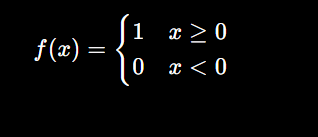





weights += learning_rate * error * X[i]

This is the perceptron learning rule.

The formula is:

W(new)​=W(old)​+η×error×X

where:

η = learning rate

error = target − prediction

X = input

If:

error = 0

then:

weights don't change


In [6]:
# Testing
print("Final Weights:", weights)
print("Final Bias:", bias)

Final Weights: [0.2 0.1]
Final Bias: -0.20000000000000004


In [7]:
print("\nIrrigation Decisions:")
labels = {
    (0, 0): "Moist soil, rain expected",
    (0, 1): "Moist soil, no rain expected",
    (1, 0): "Dry soil, rain expected",
    (1, 1): "Dry soil, no rain expected"
}


Irrigation Decisions:


In [8]:
for i in range(len(X)):
    summation = np.dot(X[i], weights) + bias
    prediction = 1 if summation >= 0 else 0
    condition = labels[tuple(X[i])]
    decision = "Turn ON irrigation" if prediction == 1 else "Keep irrigation OFF"
    print(f"Input: {X[i]} ({condition}) -> {decision}")

Input: [0 0] (Moist soil, rain expected) -> Keep irrigation OFF
Input: [0 1] (Moist soil, no rain expected) -> Keep irrigation OFF
Input: [1 0] (Dry soil, rain expected) -> Keep irrigation OFF
Input: [1 1] (Dry soil, no rain expected) -> Turn ON irrigation
